In [9]:
butce = float(input("Bütçeniz: "))
maksimum_km = int(input("Maksimum KM: "))
minimum_yil = int(input("Minimum model yılı: "))
yakit_tipleri = {"Benzin", "Dizel", "Hibrit", "Elektrik"}

In [10]:
def veriyi_yukle():
    pass

def veriyi_incele():
    pass

def eksik_verileri_bul():
    pass

def aykiri_degerleri_bul():
    pass

def arac_filtrele(butce, max_km, min_yil):
    pass

def istatistikleri_goster():
    pass

def arac_yasi_hesapla(year):
    guncel_yil = 2026 
    yas = guncel_yil - year
    return yas
ornek_yil = 2020
hesaplanan_yas = arac_yasi_hesapla(ornek_yil)
print(f"{ornek_yil} model aracın yaşı: {hesaplanan_yas}")

2020 model aracın yaşı: 6


In [11]:
class AracAnaliz:
    def __init__(self):
        self.veri_seti_adi = "ikinci_el_araclar.csv"
    def veriyi_yukle(self):
        pass
    
    def temizle(self):
        pass
        
    def analiz_et(self):
        pass
analiz_projesi = AracAnaliz()

In [12]:
import sqlite3
import pandas as pd
dosya_yolu = r"vehicles.csv.zip"
df = pd.read_csv(dosya_yolu, nrows=10000) 
conn = sqlite3.connect('araclar.db')
df.to_sql('vehicles', conn, if_exists='replace', index=False)
print(f"Harika! {len(df)} satırlık gerçek veri SQL'e başarıyla aktarıldı.")
conn.close()

Harika! 10000 satırlık gerçek veri SQL'e başarıyla aktarıldı.


In [13]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('araclar.db')

sorgu_1 = """
SELECT manufacturer, model, price 
FROM vehicles 
ORDER BY price DESC 
LIMIT 10;
"""
print("--- 1. En Pahalı 10 Araç ---")
print(pd.read_sql(sorgu_1, conn))
print("\n")

sorgu_2 = """
SELECT manufacturer, AVG(price) AS ortalama_fiyat 
FROM vehicles 
GROUP BY manufacturer;
"""
print("--- 2. Markalara Göre Ortalama Fiyat ---")

print(pd.read_sql(sorgu_2, conn).head(10)) 
print("\n")

sorgu_3 = """
SELECT manufacturer, model, year, odometer, price 
FROM vehicles 
WHERE year > 2020 AND odometer < 100000;
"""
print("--- 3. 2020 Sonrası ve 100.000 KM Altı Araçlar ---")
print(pd.read_sql(sorgu_3, conn).head(10))
print("\n")

sorgu_4 = """
SELECT AVG(price) AS otomatik_ortalama 
FROM vehicles 
WHERE region = 'prescott' AND transmission = 'automatic';
"""
print("--- 4. Prescott'taki Otomatik Araçların Ortalama Fiyatı ---")
print(pd.read_sql(sorgu_4, conn))
print("\n")

sorgu_5 = """
SELECT manufacturer, COUNT(*) AS arac_sayisi 
FROM vehicles 
GROUP BY manufacturer
ORDER BY arac_sayisi DESC;
"""
print("--- 5. Markalara Göre Araç Sayısı ---")
print(pd.read_sql(sorgu_5, conn).head(10))
print("\n")

conn.close()

--- 1. En Pahalı 10 Araç ---
  manufacturer                model      price
0    chevrolet                 None  987654321
1         ford               ranger   99999999
2      ferrari           488 spider     229500
3         None     Lamborghini Urus     229500
4         ford        2 dr victoria     213000
5         None  freightliner m2 106     145000
6         None  freightliner m2 106     145000
7         jeep             renegade     140000
8    chevrolet             corvette     130000
9       nissan                 gt-r     122995


--- 2. Markalara Göre Ortalama Fiyat ---
  manufacturer  ortalama_fiyat
0         None    20342.244306
1        acura    25606.394286
2   alfa-romeo    30382.058824
3         audi    28434.198529
4          bmw    23830.339483
5        buick    14078.435484
6     cadillac    23225.975309
7    chevrolet   671202.612607
8     chrysler    16053.153285
9        dodge    17621.427083


--- 3. 2020 Sonrası ve 100.000 KM Altı Araçlar ---
  manufacturer   

In [14]:
import pandas as pd
import numpy as np

dosya_yolu = r"vehicles.csv.zip"
df = pd.read_csv(dosya_yolu, nrows=10000)

prices = np.array(df['price'])

fiyat_mean = np.mean(prices)
fiyat_median = np.median(prices)
fiyat_std = np.std(prices)
fiyat_min = np.min(prices)
fiyat_max = np.max(prices)

print("--- Fiyat Değişimi İstatistikleri ---")
print(f"Ortalama (Mean): {fiyat_mean:,.2f}")
print(f"Medyan (Median): {fiyat_median:,.2f}")
print(f"Standart Sapma (Std): {fiyat_std:,.2f}")
print(f"Minimum Fiyat (Min): {fiyat_min:,.2f}")
print(f"Maksimum Fiyat (Max): {fiyat_max:,.2f}")

--- Fiyat Değişimi İstatistikleri ---
Ortalama (Mean): 130,303.01
Medyan (Median): 20,000.00
Standart Sapma (Std): 9,926,218.48
Minimum Fiyat (Min): 0.00
Maksimum Fiyat (Max): 987,654,321.00


In [15]:
import pandas as pd

dosya_yolu = r"vehicles.csv.zip"
df = pd.read_csv(dosya_yolu, nrows=10000)

print("--- İlk 5 Satır ---")
print(df.head())

print("\n--- Son 5 Satır ---")
print(df.tail())

print("\n--- Satır ve Sütun Sayısı ---")
print(df.shape)

print("\n--- Sütun İsimleri ---")
print(df.columns)

print("\n--- Veri Tipleri ---")
print(df.dtypes)

print("\n--- Veri Seti Genel Bilgisi ---")
df.info() 

print("\n--- İstatistiksel Özet ---")
print(df.describe())

print("\n" + "="*40)
print("SORULARIN CEVAPLARI")
print("="*40)

print(f"1. Kaç satır ve sütun var?: {df.shape[0]} satır, {df.shape[1]} sütun var.")

sayisal_sutunlar = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f"\n2. Sayısal sütunlar hangileri?:\n{sayisal_sutunlar}")

kategorik_sutunlar = df.select_dtypes(include=['object']).columns.tolist()
print(f"\n3. Kategorik sütunlar hangileri?:\n{kategorik_sutunlar}")

eksik_veriler = df.isnull().sum()
eksik_olan_sutunlar = eksik_veriler[eksik_veriler > 0]
print(f"\n4. Eksik veri bulunan sütunlar hangileri ve kaç tane eksik var?:\n{eksik_olan_sutunlar}")

tekrar_eden_sayisi = df.duplicated().sum()
if tekrar_eden_sayisi > 0:
    print(f"\n5. Tekrar eden kayıt var mı?: Evet, tam {tekrar_eden_sayisi} adet birebir kopyalanmış satır var.")
else:
    print("\n5. Tekrar eden kayıt var mı?: Hayır, kopyalanmış satır yok.")

--- İlk 5 Satır ---
           id                                                url  \
0  7222695916  https://prescott.craigslist.org/cto/d/prescott...   
1  7218891961  https://fayar.craigslist.org/ctd/d/bentonville...   
2  7221797935  https://keys.craigslist.org/cto/d/summerland-k...   
3  7222270760  https://worcester.craigslist.org/cto/d/west-br...   
4  7210384030  https://greensboro.craigslist.org/cto/d/trinit...   

                   region                         region_url  price  year  \
0                prescott    https://prescott.craigslist.org   6000   NaN   
1            fayetteville       https://fayar.craigslist.org  11900   NaN   
2            florida keys        https://keys.craigslist.org  21000   NaN   
3  worcester / central MA   https://worcester.craigslist.org   1500   NaN   
4              greensboro  https://greensboro.craigslist.org   4900   NaN   

  manufacturer model condition cylinders  ... size  type paint_color  \
0          NaN   NaN       NaN      

In [16]:
df = df.drop_duplicates()
toplam_eksik = df.isnull().sum().sum()
print(f"Temizlik öncesi toplam eksik hücre sayısı: {toplam_eksik}")

if 'odometer' in df.columns:
    df['odometer'] = df['odometer'].fillna(df['odometer'].median())

if 'year' in df.columns:
    df['year'] = df['year'].fillna(df['year'].median())

df = df.dropna()

print(f"Temizlik sonrası kalan toplam satır sayısı: {df.shape[0]}")
print(f"Temizlik sonrası kalan eksik hücre sayısı: {df.isnull().sum().sum()}")

Temizlik öncesi toplam eksik hücre sayısı: 36685
Temizlik sonrası kalan toplam satır sayısı: 0
Temizlik sonrası kalan eksik hücre sayısı: 0


In [17]:
dosya_yolu = r"vehicles.csv.zip"
df = pd.read_csv(dosya_yolu, nrows=10000)

df = df.drop_duplicates()
df['odometer'] = df['odometer'].fillna(df['odometer'].median())
df['year'] = df['year'].fillna(df['year'].median())
df = df.dropna(subset=['price', 'manufacturer', 'model'])

print(f"Kurtarılan ve temizlenen araç sayısı: {df.shape[0]}")

Kurtarılan ve temizlenen araç sayısı: 9415


In [18]:
fiyat_ortalama = df['price'].mean()
fiyat_medyan = df['price'].median()
fiyat_varyans = df['price'].var()
fiyat_std = df['price'].std()
fiyat_min = df['price'].min()
fiyat_max = df['price'].max()
fiyat_q1 = df['price'].quantile(0.25)
fiyat_q3 = df['price'].quantile(0.75)

print("--- Fiyat (Price) Değişkeni İstatistikleri ---")
print(f"Ortalama: {fiyat_ortalama:,.2f}")
print(f"Medyan: {fiyat_medyan:,.2f}")
print(f"Varyans: {fiyat_varyans:,.2f}")
print(f"Standart Sapma: {fiyat_std:,.2f}")
print(f"Minimum: {fiyat_min:,.2f}")
print(f"Maksimum: {fiyat_max:,.2f}")
print(f"Q1 (%25. Çeyreklik): {fiyat_q1:,.2f}")
print(f"Q3 (%75. Çeyreklik): {fiyat_q3:,.2f}")

print("\n--- Veri Bilimci Yorumu ---")

if fiyat_ortalama > fiyat_medyan:
    print("YORUM: Price değişkeninde ortalamanın medyandan oldukça yüksek olması, veri setindeki çok pahalı lüks araçların (veya hatalı girilmiş trilyonluk ilanların) ortalamayı yukarı çektiğini ve dağılımın 'sağa çarpık' hale geldiğini düşündürmektedir.")
elif fiyat_ortalama < fiyat_medyan:
    print("YORUM: Price değişkeninde ortalama medyandan düşük. Dağılım sola çarpık.")
else:
    print("YORUM: Ortalama ve medyan birbirine çok yakın, dağılım dengeli.")

--- Fiyat (Price) Değişkeni İstatistikleri ---
Ortalama: 32,236.96
Medyan: 20,900.00
Varyans: 1,061,881,923,977.43
Standart Sapma: 1,030,476.55
Minimum: 0.00
Maksimum: 99,999,999.00
Q1 (%25. Çeyreklik): 10,200.00
Q3 (%75. Çeyreklik): 29,995.00

--- Veri Bilimci Yorumu ---
YORUM: Price değişkeninde ortalamanın medyandan oldukça yüksek olması, veri setindeki çok pahalı lüks araçların (veya hatalı girilmiş trilyonluk ilanların) ortalamayı yukarı çektiğini ve dağılımın 'sağa çarpık' hale geldiğini düşündürmektedir.


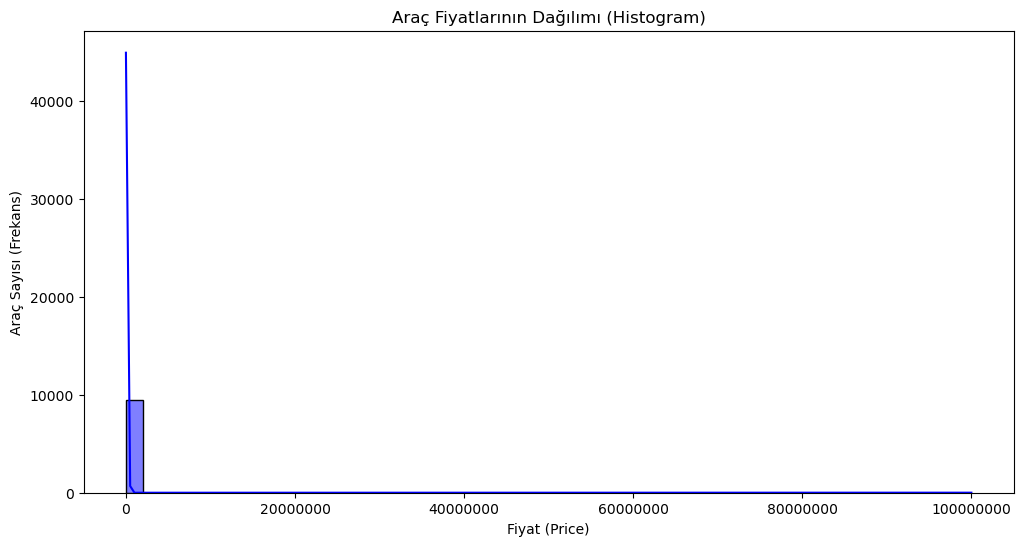

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.histplot(df['price'], bins=50, kde=True, color='blue')
plt.ticklabel_format(style='plain', axis='x')

plt.title("Araç Fiyatlarının Dağılımı (Histogram)")
plt.xlabel("Fiyat (Price)")
plt.ylabel("Araç Sayısı (Frekans)")
plt.show()

In [20]:
ortalama_fiyat = df['price'].mean()
ortalamadan_pahali_arac_sayisi = len(df[df['price'] > ortalama_fiyat])
toplam_arac_sayisi = len(df)
olasilik_fiyat = ortalamadan_pahali_arac_sayisi / toplam_arac_sayisi
print(f"1. Bir aracın fiyatının ortalamanın ({ortalama_fiyat:,.2f}) üzerinde olma olasılığı: % {olasilik_fiyat * 100:.2f}")

yuz_bin_km_alti_arac_sayisi = len(df[df['odometer'] < 100000])
olasilik_km = yuz_bin_km_alti_arac_sayisi / toplam_arac_sayisi
print(f"2. Bir aracın 100.000 km'den düşük olma olasılığı: % {olasilik_km * 100:.2f}")

1. Bir aracın fiyatının ortalamanın (32,236.96) üzerinde olma olasılığı: % 20.53
2. Bir aracın 100.000 km'den düşük olma olasılığı: % 65.35


In [21]:
import scipy.stats as stats
otomatik_fiyatlari = df[df['transmission'] == 'automatic']['price']
manuel_fiyatlari = df[df['transmission'] == 'manual']['price']

otomatik_fiyatlari = otomatik_fiyatlari.dropna()
manuel_fiyatlari = manuel_fiyatlari.dropna()

t_istatistigi, p_value = stats.ttest_ind(otomatik_fiyatlari, manuel_fiyatlari, equal_var=False)
print(f"Hesaplanan p-value değeri: {p_value}")

print("\n--- Hipotez Testi Sonucu ---")
if p_value < 0.05:
    print("YORUM: p < 0.05 olduğu için H0 reddedildi. Veri setinde otomatik ve manuel araçların fiyatları arasında istatistiksel olarak anlamlı bir fark bulunmaktadır."[cite: 12])
else:
    print("YORUM: p >= 0.05 olduğu için H0 reddedilemedi. Otomatik ve manuel araç fiyatları arasındaki fark istatistiksel olarak anlamlı değildir, tesadüfi olabilir.")

Hesaplanan p-value değeri: 0.18084456331525828

--- Hipotez Testi Sonucu ---
YORUM: p >= 0.05 olduğu için H0 reddedilemedi. Otomatik ve manuel araç fiyatları arasındaki fark istatistiksel olarak anlamlı değildir, tesadüfi olabilir.


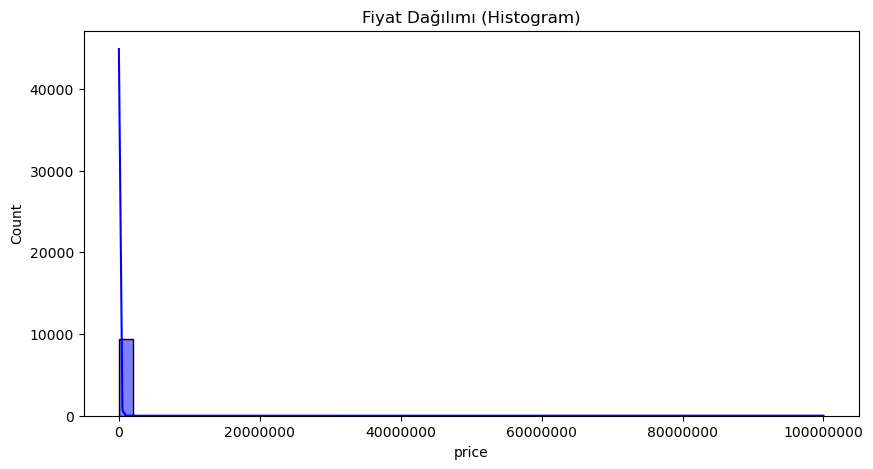

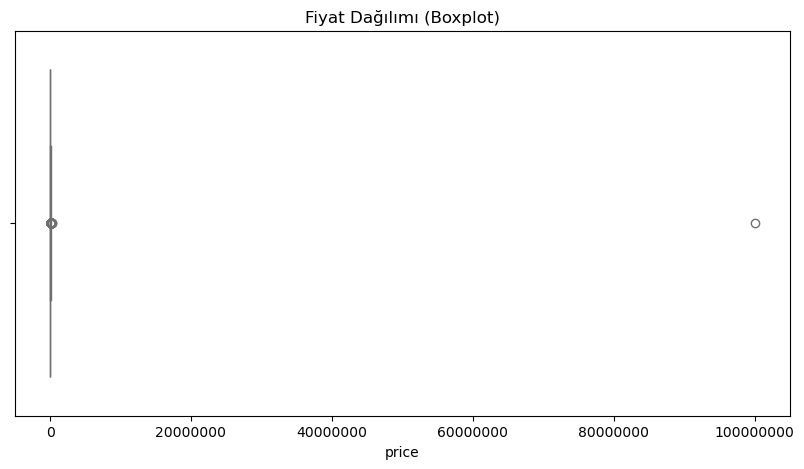

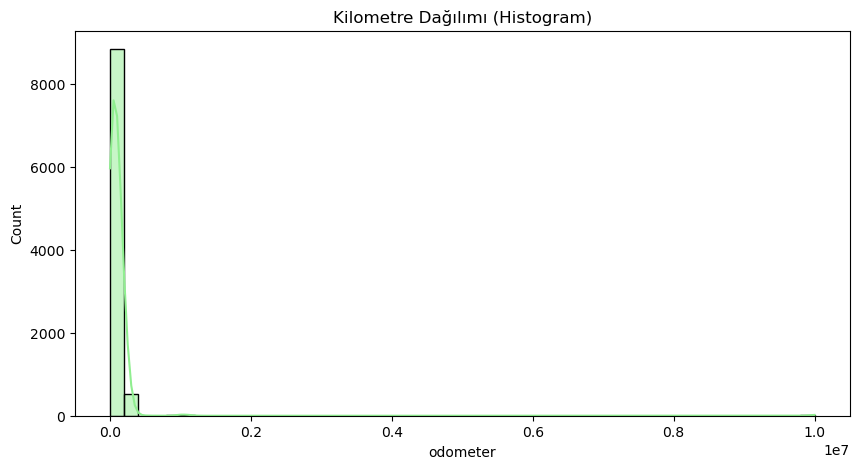

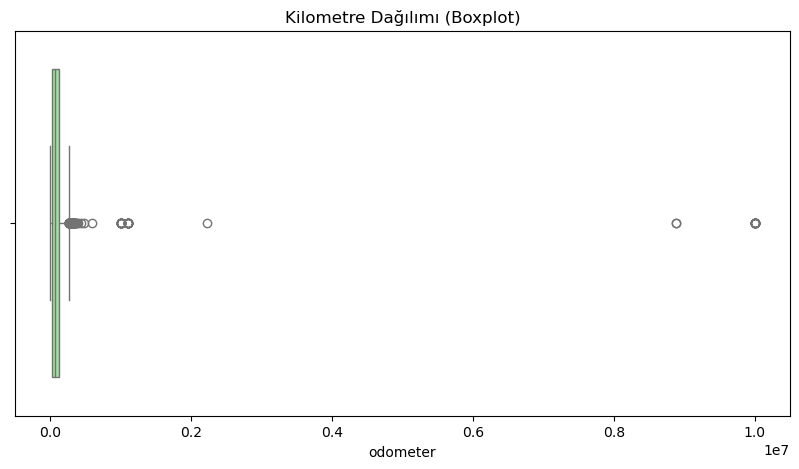

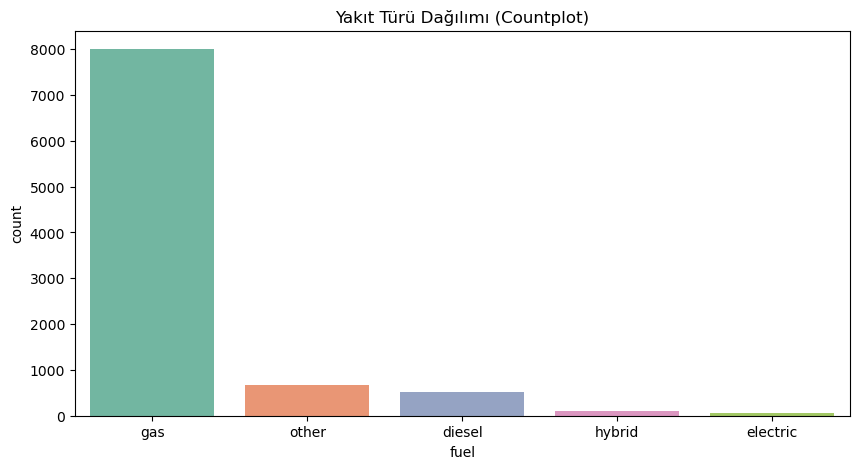

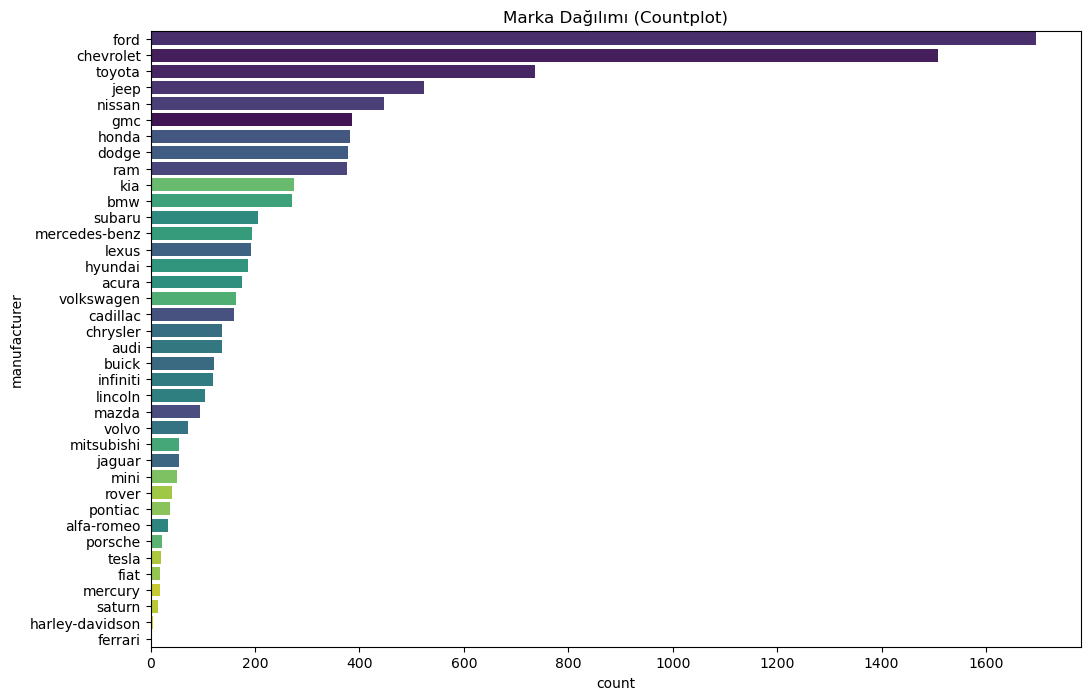

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 5)

plt.figure()
sns.histplot(df['price'], bins=50, kde=True, color='blue')
plt.ticklabel_format(style='plain', axis='x') 
plt.title("Fiyat Dağılımı (Histogram)")
plt.show()

plt.figure()
sns.boxplot(x=df['price'], color='skyblue')
plt.ticklabel_format(style='plain', axis='x')
plt.title("Fiyat Dağılımı (Boxplot)")
plt.show()

plt.figure()
sns.histplot(df['odometer'], bins=50, kde=True, color='lightgreen')
plt.title("Kilometre Dağılımı (Histogram)")
plt.show()

plt.figure()
sns.boxplot(x=df['odometer'], color='lightgreen')
plt.title("Kilometre Dağılımı (Boxplot)")
plt.show()

plt.figure()
sns.countplot(data=df, x='fuel', hue='fuel', palette='Set2', legend=False)
plt.title("Yakıt Türü Dağılımı (Countplot)")
plt.show()

plt.figure(figsize=(12, 8))
sns.countplot(data=df, y='manufacturer', hue='manufacturer', palette='viridis', order=df['manufacturer'].value_counts().index , legend=False)
plt.title("Marka Dağılımı (Countplot)")
plt.show()

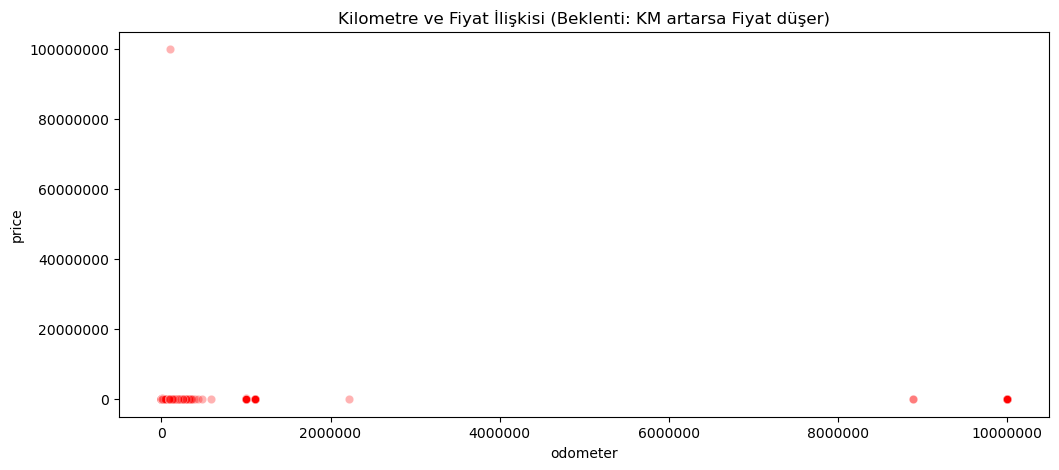

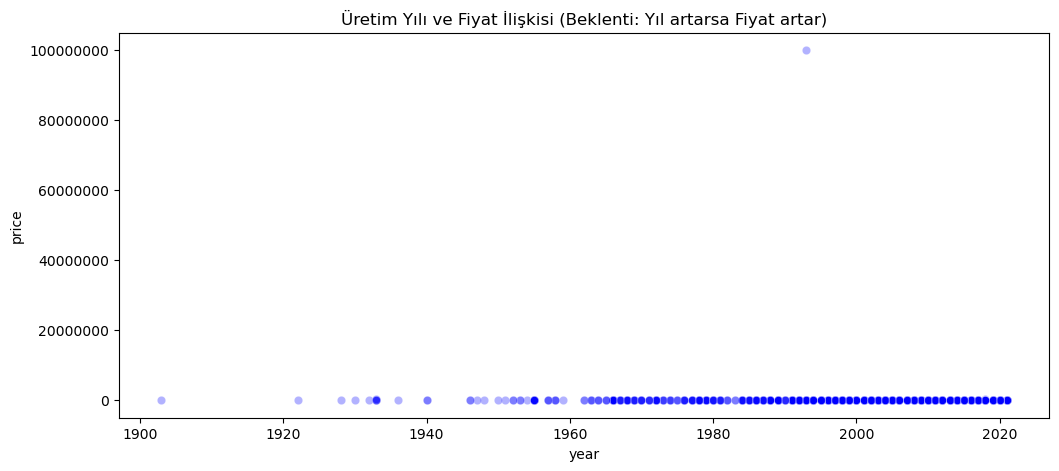

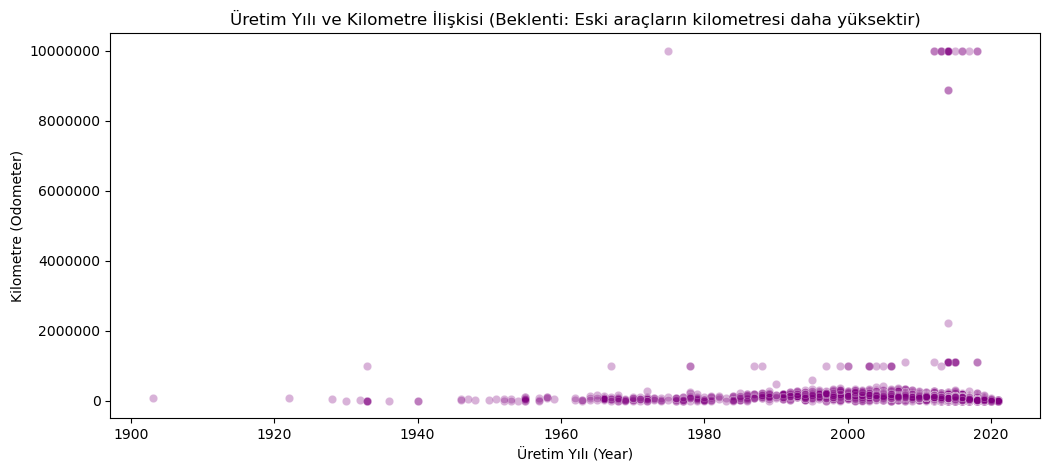

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (12, 5)
plt.figure()
sns.scatterplot(data=df, x='odometer', y='price', alpha=0.3, color='red')
plt.ticklabel_format(style='plain', axis='both')
plt.title("Kilometre ve Fiyat İlişkisi (Beklenti: KM artarsa Fiyat düşer)")
plt.show()

plt.figure()
sns.scatterplot(data=df, x='year', y='price', alpha=0.3, color='blue')
plt.ticklabel_format(style='plain', axis='both')
plt.title("Üretim Yılı ve Fiyat İlişkisi (Beklenti: Yıl artarsa Fiyat artar)")
plt.show()

plt.figure(figsize=(12, 5))
sns.scatterplot(data=df, x='year', y='odometer', alpha=0.3, color='purple')
plt.ticklabel_format(style='plain', axis='both')
plt.title("Üretim Yılı ve Kilometre İlişkisi (Beklenti: Eski araçların kilometresi daha yüksektir)")
plt.xlabel("Üretim Yılı (Year)")
plt.ylabel("Kilometre (Odometer)")
plt.show()

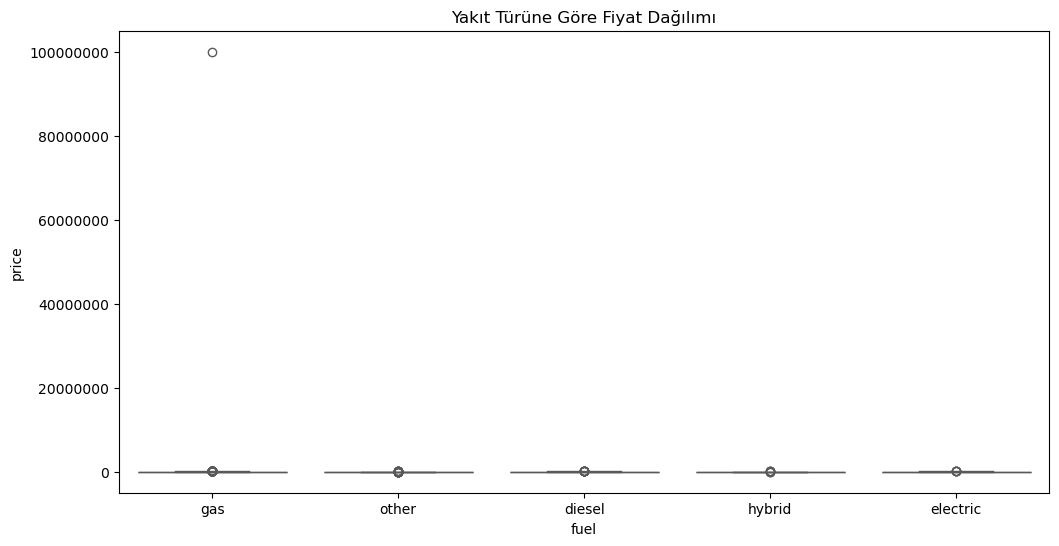

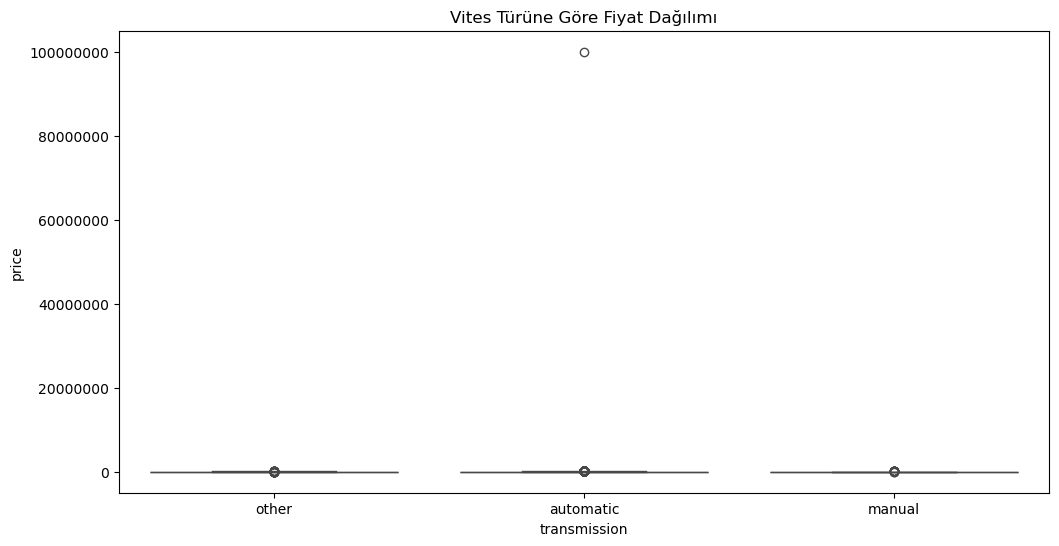

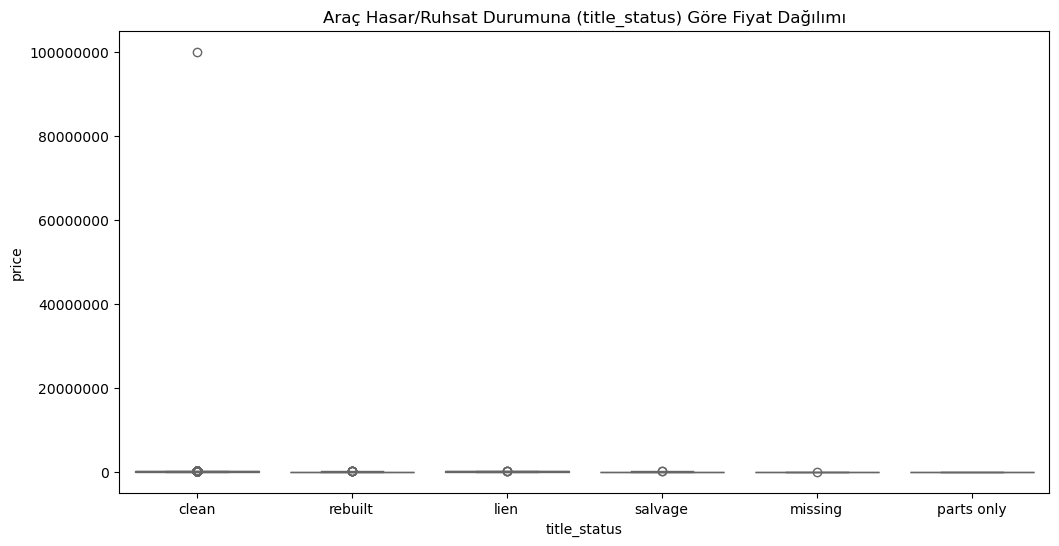

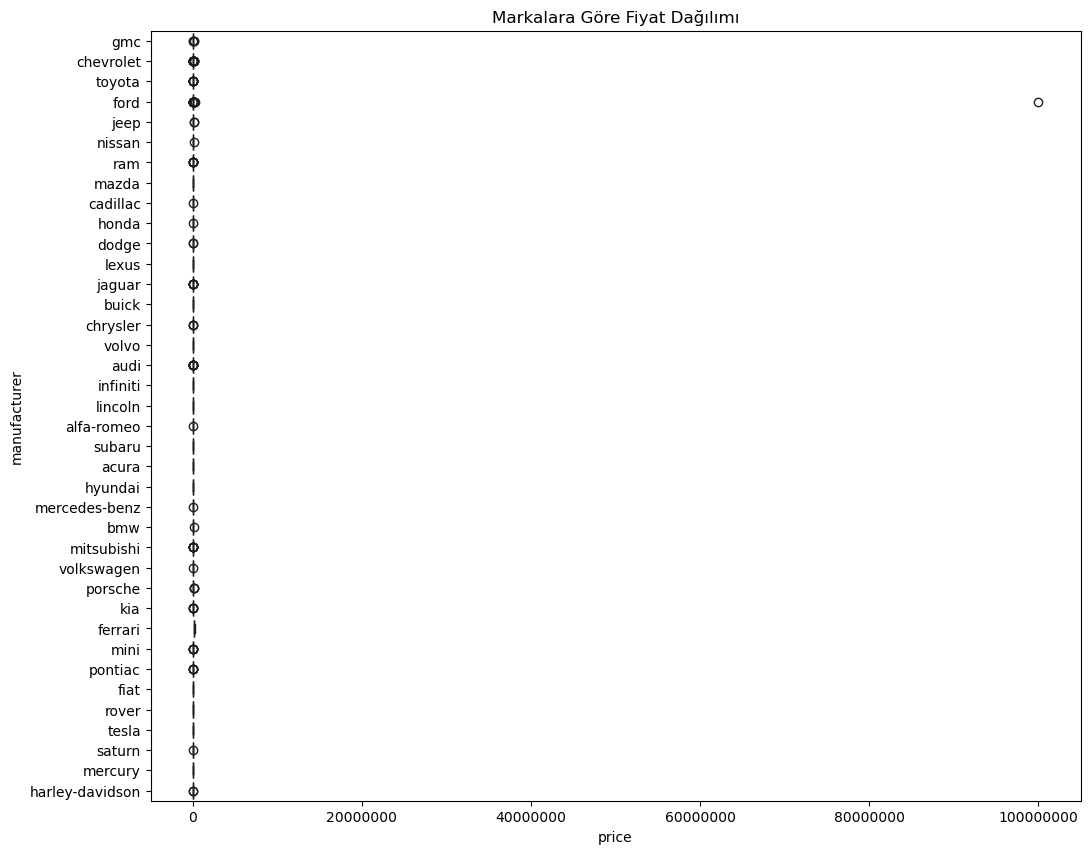

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (12, 6)

plt.figure()
sns.boxplot(data=df, x='fuel', y='price', hue='fuel', palette='Set2', legend=False)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Yakıt Türüne Göre Fiyat Dağılımı")
plt.show()

plt.figure()
sns.boxplot(data=df, x='transmission', y='price', hue='transmission', palette='Set1', legend=False)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Vites Türüne Göre Fiyat Dağılımı")
plt.show()

plt.figure()
sns.boxplot(data=df, x='title_status', y='price', hue='title_status', palette='Set3', legend=False)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Araç Hasar/Ruhsat Durumuna (title_status) Göre Fiyat Dağılımı")
plt.show()

plt.figure(figsize=(12, 10))
sns.boxplot(data=df, y='manufacturer', x='price', hue='manufacturer', palette='viridis', legend=False)
plt.ticklabel_format(style='plain', axis='x')
plt.title("Markalara Göre Fiyat Dağılımı")
plt.show()

--- Korelasyon Matrisi ---
            price  odometer      year
price     1.00000 -0.002160 -0.017140
odometer -0.00216  1.000000 -0.065741
year     -0.01714 -0.065741  1.000000


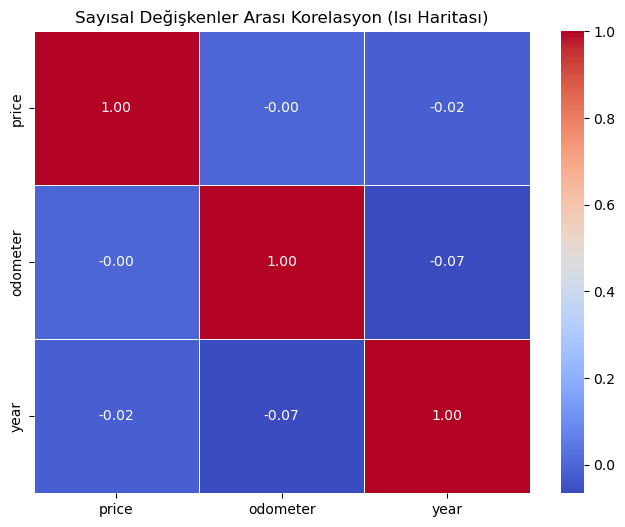


--- Veri Bilimci Yorumu ---
ÖNEMLİ BİLGİ: Korelasyon nedensellik değildir.


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sayisal_df = df[['price', 'odometer', 'year']]
korelasyon_matrisi = sayisal_df.corr()
print("--- Korelasyon Matrisi ---")
print(korelasyon_matrisi)

plt.figure(figsize=(8, 6))
sns.heatmap(korelasyon_matrisi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Sayısal Değişkenler Arası Korelasyon (Isı Haritası)")
plt.show()
print("\n--- Veri Bilimci Yorumu ---")
print("ÖNEMLİ BİLGİ: Korelasyon nedensellik değildir.")

In [26]:
print("--- PRICE (Fiyat) İçin IQR Hesaplaması ---")
Q1_p = df['price'].quantile(0.25)
Q3_p = df['price'].quantile(0.75)
IQR_p = Q3_p - Q1_p

alt_sinir_p = Q1_p - (1.5 * IQR_p)
ust_sinir_p = Q3_p + (1.5 * IQR_p)

print(f"Matematiksel Alt Sınır: {alt_sinir_p:,.2f} | Üst Sınır: {ust_sinir_p:,.2f}")

print("\n--- ODOMETER (Kilometre) İçin IQR Hesaplaması ---")
Q1_k = df['odometer'].quantile(0.25)
Q3_k = df['odometer'].quantile(0.75)
IQR_k = Q3_k - Q1_k

alt_sinir_k = Q1_k - (1.5 * IQR_k)
ust_sinir_k = Q3_k + (1.5 * IQR_k)

print(f"Matematiksel Alt Sınır: {alt_sinir_k:,.2f} | Üst Sınır: {ust_sinir_k:,.2f}")

print("\n--- YORUM VE MANTIK KONTROLÜ ---")
km_ornek = 650000
if km_ornek > ust_sinir_k:
    print(f"YORUM: 650.000 KM, matematiksel üst sınırın ({ust_sinir_k:,.0f}) çok üzerindedir.")
    print("Ancak Yönerge kuralı gereği körü körüne silmiyoruz: Bu bir ticari çekici veya kamyonet ise gerçek olabilir. Fakat 10 Milyon KM kesinlikle sahtedir.")

print("\n--- VERİ TEMİZLİĞİ (CERRAHİ MÜDAHALE) ---")
df_temiz = df[(df['price'] >= 500) & (df['price'] <= ust_sinir_p)]
df_temiz = df_temiz[(df_temiz['odometer'] >= 0) & (df_temiz['odometer'] <= ust_sinir_k)]

print(f"Temizlik Öncesi Araç Sayısı: {len(df)}")
print(f"Temizlik Sonrası Araç Sayısı: {len(df_temiz)}")
print(f"Veri setinden çöpe atılan absürt/aykırı ilan sayısı: {len(df) - len(df_temiz)}")

df = df_temiz

--- PRICE (Fiyat) İçin IQR Hesaplaması ---
Matematiksel Alt Sınır: -19,492.50 | Üst Sınır: 59,687.50

--- ODOMETER (Kilometre) İçin IQR Hesaplaması ---
Matematiksel Alt Sınır: -114,500.00 | Üst Sınır: 265,500.00

--- YORUM VE MANTIK KONTROLÜ ---
YORUM: 650.000 KM, matematiksel üst sınırın (265,500) çok üzerindedir.
Ancak Yönerge kuralı gereği körü körüne silmiyoruz: Bu bir ticari çekici veya kamyonet ise gerçek olabilir. Fakat 10 Milyon KM kesinlikle sahtedir.

--- VERİ TEMİZLİĞİ (CERRAHİ MÜDAHALE) ---
Temizlik Öncesi Araç Sayısı: 9415
Temizlik Sonrası Araç Sayısı: 8856
Veri setinden çöpe atılan absürt/aykırı ilan sayısı: 559


In [27]:
pd.options.mode.chained_assignment = None
df['car_age'] = 2026 - df['year']
df.loc[df['car_age'] == 0, 'car_age'] = 1
df['km_per_year'] = df['odometer'] / df['car_age']
df['is_4wd'] = (df['drive'] == '4wd').astype(int)
premium_markalar = ['bmw', 'mercedes-benz', 'audi', 'volvo', 'lexus', 'porsche']
df['is_premium'] = df['manufacturer'].isin(premium_markalar).astype(int)
df['high_mileage'] = (df['odometer'] > 150000).astype(int)

def segment_belirle(arac_tipi):
    if pd.isna(arac_tipi):
        return 'Bilinmiyor'
    
    arac_tipi = str(arac_tipi).lower()
    
    if arac_tipi in ['sedan', 'coupe', 'hatchback', 'convertible']:
        return 'Binek'
    elif arac_tipi in ['suv', 'offroad']:
        return 'SUV'
    elif arac_tipi in ['truck', 'pickup', 'van', 'mini-van', 'bus']:
        return 'Ticari_ve_Buyuk'
    else:
        return 'Diger'
df['segment'] = df['type'].apply(segment_belirle)

yeni_sutunlar = ['price', 'car_age', 'km_per_year', 'is_4wd', 'is_premium', 'high_mileage', 'segment']
print(df[yeni_sutunlar].head(10))

    price  car_age  km_per_year  is_4wd  is_premium  high_mileage  \
27  33590     12.0  4826.916667       0           0             0   
28  22590     16.0  4451.812500       0           0             0   
29  39590      6.0  3193.333333       0           0             0   
30  30990      9.0  4569.333333       0           0             0   
31  15000     13.0  9846.153846       0           0             0   
32  27990     14.0  4906.857143       1           0             0   
33  34590     10.0  2949.900000       1           0             0   
34  35000      7.0  6142.857143       1           0             0   
35  29990     10.0  1730.200000       1           0             0   
36  38590     15.0  2015.800000       0           0             0   

            segment  
27  Ticari_ve_Buyuk  
28  Ticari_ve_Buyuk  
29  Ticari_ve_Buyuk  
30  Ticari_ve_Buyuk  
31  Ticari_ve_Buyuk  
32  Ticari_ve_Buyuk  
33  Ticari_ve_Buyuk  
34  Ticari_ve_Buyuk  
35  Ticari_ve_Buyuk  
36            Diger 

In [28]:
print("--- ORİJİNAL ÖZELLİKLERİN FİYAT (PRICE) İLE KORELASYONU ---")
korelasyon_yil = df['year'].corr(df['price'])
korelasyon_km = df['odometer'].corr(df['price'])
print(f"Üretim Yılı (year) ve Fiyat: {korelasyon_yil:.3f}")
print(f"Toplam KM (odometer) ve Fiyat: {korelasyon_km:.3f}")

print("\n--- YENİ ÜRETTİĞİMİZ ÖZELLİKLERİN FİYAT (PRICE) İLE KORELASYONU ---")
korelasyon_yas = df['car_age'].corr(df['price'])
korelasyon_yillik_km = df['km_per_year'].corr(df['price'])
korelasyon_4wd = df['is_4wd'].corr(df['price'])
korelasyon_premium = df['is_premium'].corr(df['price'])
korelasyon_yuksek_km = df['high_mileage'].corr(df['price'])

print(f"Araç Yaşı (car_age) ve Fiyat: {korelasyon_yas:.3f}")
print(f"Yıllık Ortalama KM (km_per_year) ve Fiyat: {korelasyon_yillik_km:.3f}")
print(f"4x4 Çekiş (is_4wd) ve Fiyat: {korelasyon_4wd:.3f}")
print(f"Premium Marka (is_premium) ve Fiyat: {korelasyon_premium:.3f}")
print(f"Yüksek KM (>150k) (high_mileage) ve Fiyat: {korelasyon_yuksek_km:.3f}")

print("\n--- VERİ BİLİMCİ YORUMU ---")

if abs(korelasyon_yillik_km) > abs(korelasyon_km):
    print("YORUM: km_per_year değişkeni fiyatı açıklama konusunda toplam kilometreden daha güçlü bir ilişkiye sahip!")
    print("İşte Feature Engineering mantığı tam olarak burada parlıyor!")
else:
    print("YORUM: Orijinal odometer (toplam KM) değişkeni fiyatı açıklama konusunda hala güçlü.")
    print("Ancak km_per_year, is_premium ve is_4wd gibi yeni özellikler makine öğrenmesi modelimize yepyeni bir yıpranma ve lüks algısı katacak.")

--- ORİJİNAL ÖZELLİKLERİN FİYAT (PRICE) İLE KORELASYONU ---
Üretim Yılı (year) ve Fiyat: 0.455
Toplam KM (odometer) ve Fiyat: -0.591

--- YENİ ÜRETTİĞİMİZ ÖZELLİKLERİN FİYAT (PRICE) İLE KORELASYONU ---
Araç Yaşı (car_age) ve Fiyat: -0.455
Yıllık Ortalama KM (km_per_year) ve Fiyat: -0.350
4x4 Çekiş (is_4wd) ve Fiyat: 0.314
Premium Marka (is_premium) ve Fiyat: 0.053
Yüksek KM (>150k) (high_mileage) ve Fiyat: -0.414

--- VERİ BİLİMCİ YORUMU ---
YORUM: Orijinal odometer (toplam KM) değişkeni fiyatı açıklama konusunda hala güçlü.
Ancak km_per_year, is_premium ve is_4wd gibi yeni özellikler makine öğrenmesi modelimize yepyeni bir yıpranma ve lüks algısı katacak.


In [29]:
secilen_sutunlar = ['price', 'odometer', 'car_age', 'km_per_year', 'is_4wd', 'is_premium', 
                    'high_mileage', 'transmission', 'fuel', 'manufacturer', 'title_status', 'segment']

df_ml = df[secilen_sutunlar]
print(f"Encoding Öncesi Sütun Sayısı: {df_ml.shape[1]}")
kategorik_sutunlar = ['transmission', 'fuel', 'manufacturer', 'title_status', 'segment']
df_encoded = pd.get_dummies(df_ml, columns=kategorik_sutunlar, drop_first=True)
df_encoded = df_encoded.astype(int)

print(f"Encoding Sonrası Sütun Sayısı: {df_encoded.shape[1]}")
print("\n---Yapay Zekaya Hazır, Tamamen Sayısal Tablonun İlk 3 Satırı ---")
print(df_encoded.head(3))

Encoding Öncesi Sütun Sayısı: 12
Encoding Sonrası Sütun Sayısı: 58

---Yapay Zekaya Hazır, Tamamen Sayısal Tablonun İlk 3 Satırı ---
    price  odometer  car_age  km_per_year  is_4wd  is_premium  high_mileage  \
27  33590     57923       12         4826       0           0             0   
28  22590     71229       16         4451       0           0             0   
29  39590     19160        6         3193       0           0             0   

    transmission_manual  transmission_other  fuel_electric  ...  \
27                    0                   1              0  ...   
28                    0                   1              0  ...   
29                    0                   1              0  ...   

    manufacturer_volvo  title_status_lien  title_status_missing  \
27                   0                  0                     0   
28                   0                  0                     0   
29                   0                  0                     0   

    title_st

In [30]:
print("--- Veri Seti Yapı Kontrolü (Röntgen) ---")
df_encoded.info()

--- Veri Seti Yapı Kontrolü (Röntgen) ---
<class 'pandas.core.frame.DataFrame'>
Index: 8856 entries, 27 to 9999
Data columns (total 58 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   price                         8856 non-null   int64
 1   odometer                      8856 non-null   int64
 2   car_age                       8856 non-null   int64
 3   km_per_year                   8856 non-null   int64
 4   is_4wd                        8856 non-null   int64
 5   is_premium                    8856 non-null   int64
 6   high_mileage                  8856 non-null   int64
 7   transmission_manual           8856 non-null   int64
 8   transmission_other            8856 non-null   int64
 9   fuel_electric                 8856 non-null   int64
 10  fuel_gas                      8856 non-null   int64
 11  fuel_hybrid                   8856 non-null   int64
 12  fuel_other                    8856 non-null   int64


In [31]:
print("\n--- Üretim Yılına Göre Fiyat Analizi (Resampling) ---")
resampling_ozeti = df.groupby('year')['price'].agg(['mean', 'std']).round(2)
resampling_ozeti.columns = ['Ortalama Fiyat', 'Standart Sapma']
print(resampling_ozeti.tail(10))


--- Üretim Yılına Göre Fiyat Analizi (Resampling) ---
        Ortalama Fiyat  Standart Sapma
year                                  
2012.0        19537.15         9673.13
2013.0        19063.96         9373.85
2014.0        21796.05        10169.94
2015.0        24404.73        10638.26
2016.0        25396.89        10264.98
2017.0        27430.96         8705.50
2018.0        28576.66         9533.42
2019.0        31417.97         9701.80
2020.0        33451.58        10095.15
2021.0        30806.93        10685.88


In [32]:
from sklearn.linear_model import LinearRegression
X = df_encoded[['odometer']]
y = df_encoded['price']

model = LinearRegression()
model.fit(X, y)
katsayi = model.coef_[0]
kesisim = model.intercept_

print("--- Makine Öğrenmesi (Basit Regresyon) Sonuçları ---")
print(f"Regresyon Katsayısı (Eğim / Coefficient): {katsayi:.5f}")
print(f"Başlangıç Noktası (Y-Kesişim / Intercept): {kesisim:.2f}")

print("\n--- Veri Bilimci Yorumu ---")
print(f"Diğer değişkenleri hesaba katmadan kilometredeki 1 birim (1 KM) artış, "
      f"fiyatın yaklaşık {abs(katsayi):.5f} Dolar {'azalmasıyla' if katsayi < 0 else 'artmasıyla'} ilişkilidir.")

--- Makine Öğrenmesi (Basit Regresyon) Sonuçları ---
Regresyon Katsayısı (Eğim / Coefficient): -0.11799
Başlangıç Noktası (Y-Kesişim / Intercept): 31320.22

--- Veri Bilimci Yorumu ---
Diğer değişkenleri hesaba katmadan kilometredeki 1 birim (1 KM) artış, fiyatın yaklaşık 0.11799 Dolar azalmasıyla ilişkilidir.


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X_yas = df_encoded[['car_age']]
y = df_encoded['price']

model_yas = LinearRegression()
model_yas.fit(X_yas, y)
katsayi_yas = model_yas.coef_[0]

print("--- İKİNCİ REGRESYON (Araç Yaşı) ---")
print(f"Araç Yaşı Katsayısı: {katsayi_yas:.2f}")
print("YORUM: Önceki aşamada KM katsayısı -0.11 çıkmıştı (1 KM artış 11 cent kayıp).")
print(f"Yaş katsayısı ise {katsayi_yas:.2f} çıktı. Yani araç 1 yaş yaşlandığında fiyatı çok daha dramatik bir şekilde düşüyor.")

ekstra_ozellikler = ['km_per_year', 'is_4wd', 'is_premium', 'high_mileage']
segment_sutunlari = [col for col in df_encoded.columns if 'segment_' in col]
cikarilacaklar = ['price'] + ekstra_ozellikler + segment_sutunlari

X1 = df_encoded.drop(columns=cikarilacaklar)
model_1 = LinearRegression()
model_1.fit(X1, y)
tahminler_1 = model_1.predict(X1)
r2_model_1 = r2_score(y, tahminler_1)

print("\n--- FEATURE ENGINEERING EKLENMEDEN MODEL (Model 1) ---")
print(f"Model 1 (Ham Veriler) R² Skoru: {r2_model_1:.4f}")
print("YORUM: R² skoru, modelin araba fiyatlarını yüzde kaç oranında doğru açıklayabildiğini gösterir.")

--- İKİNCİ REGRESYON (Araç Yaşı) ---
Araç Yaşı Katsayısı: -635.57
YORUM: Önceki aşamada KM katsayısı -0.11 çıkmıştı (1 KM artış 11 cent kayıp).
Yaş katsayısı ise -635.57 çıktı. Yani araç 1 yaş yaşlandığında fiyatı çok daha dramatik bir şekilde düşüyor.

--- FEATURE ENGINEERING EKLENMEDEN MODEL (Model 1) ---
Model 1 (Ham Veriler) R² Skoru: 0.5651
YORUM: R² skoru, modelin araba fiyatlarını yüzde kaç oranında doğru açıklayabildiğini gösterir.


In [34]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X2 = df_encoded.drop(columns=['price'])
y = df_encoded['price']

model_2 = LinearRegression()
model_2.fit(X2, y)
tahminler_2 = model_2.predict(X2)
r2_model_2 = r2_score(y, tahminler_2)

print("--- MODEL KARŞILAŞTIRMASI ---")
print(f"Model 1 (Ham Veriler) R² Skoru: 0.5651")
print(f"Model 2 (Feature Engineering) R² Skoru: {r2_model_2:.4f}")

if r2_model_2 > 0.5651:
    print(f"YORUM: Kesinlikle geliştirdi! Kendi ürettiğimiz özellikler modelin başarısını {(r2_model_2 - 0.5651):.4f} puan artırdı.")
else:
    print("YORUM: Beklenen artış olmadı. Belki de ürettiğimiz özellikler fiyatı açıklamada yeterince güçlü değildi.")


katsayilar_tablosu = pd.DataFrame({
    'Değişken': X2.columns,
    'Katsayı Değeri (Dolar)': model_2.coef_
})

katsayilar_tablosu = katsayilar_tablosu.sort_values(by='Katsayı Değeri (Dolar)', ascending=False)

print("\n--- KATSAYILAR (Fiyatı En Çok Etkileyen Özellikler) ---")
print("Fiyatı en çok ARTIRAN ilk 5 özellik:")
print(katsayilar_tablosu.head(5))

print("\nFiyatı en çok DÜŞÜREN ilk 5 özellik:")
print(katsayilar_tablosu.tail(5))

--- MODEL KARŞILAŞTIRMASI ---
Model 1 (Ham Veriler) R² Skoru: 0.5651
Model 2 (Feature Engineering) R² Skoru: 0.6529
YORUM: Kesinlikle geliştirdi! Kendi ürettiğimiz özellikler modelin başarısını 0.0878 puan artırdı.

--- KATSAYILAR (Fiyatı En Çok Etkileyen Özellikler) ---
Fiyatı en çok ARTIRAN ilk 5 özellik:
                Değişken  Katsayı Değeri (Dolar)
44    manufacturer_tesla            17397.843775
39  manufacturer_porsche             6074.030757
3                 is_4wd             5197.563597
5           high_mileage             4935.167626
27   manufacturer_jaguar             2392.447361

Fiyatı en çok DÜŞÜREN ilk 5 özellik:
                   Değişken  Katsayı Değeri (Dolar)
49     title_status_missing            -9927.307254
36  manufacturer_mitsubishi           -10162.238302
29         manufacturer_kia           -10784.674373
8             fuel_electric           -11256.590374
20        manufacturer_fiat           -13639.583738


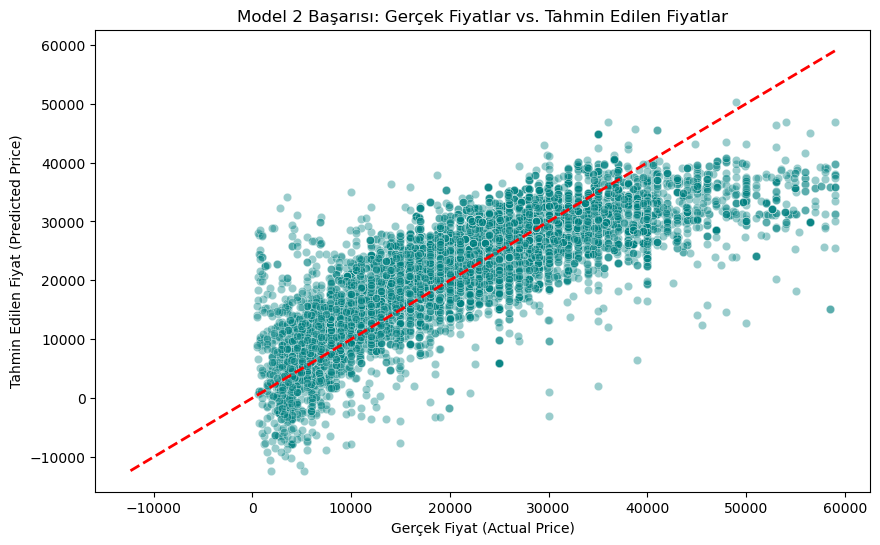

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y, y=tahminler_2, alpha=0.4, color='teal')
min_deger = min(y.min(), tahminler_2.min())
max_deger = max(y.max(), tahminler_2.max())
plt.plot([min_deger, max_deger], [min_deger, max_deger], color='red', linestyle='--', linewidth=2)
plt.ticklabel_format(style='plain', axis='both')
plt.title("Model 2 Başarısı: Gerçek Fiyatlar vs. Tahmin Edilen Fiyatlar")
plt.xlabel("Gerçek Fiyat (Actual Price)")
plt.ylabel("Tahmin Edilen Fiyat (Predicted Price)")

plt.show()

In [36]:
import pandas as pd

hata = y - tahminler_2
hata_tablosu = pd.DataFrame({
    'Gerçek': y,
    'Tahmin': tahminler_2.round(0),
    'Hata': hata.round(0)
})

hata_tablosu['Mutlak_Hata'] = hata_tablosu['Hata'].abs()
en_kotu_10_tahmin = hata_tablosu.sort_values(by='Mutlak_Hata', ascending=False).head(10)

print("--- EN KÖTÜ TAHMİN EDİLEN 10 ARAÇ ---")
print(en_kotu_10_tahmin[['Gerçek', 'Tahmin', 'Hata']])

print("\n--- Veri Bilimci Yorumu (Neden Kötü Tahmin Yaptı?) ---")
print("YORUM: Tabloya baktığımızda modelin en büyük sapmaları milyonluk/çok yüksek rakamlı araçlarda veya aşırı ucuz fiyatlı klasik/hasarlı araçlarda yaptığını görürüz.")
print("Model ortalama bir arabanın piyasasını (örneğin 20 bin dolarlık sedanları) çok iyi öğrenmiştir. Ancak özel seri, modifiyeli, nadir bulunan klasik araçlar veya pert kayıtlı otomobillerde standart formüller işe yaramaz.")
print("ÇÖZÜM: Yönergenin dediği gibi 'yeni feature geliştirme fikri' tam da burada doğar. İleride arabanın 'Hasar Kaydı (accident)' veya 'Koleksiyonluk/Özel Seri' olup olmadığını belirten yeni sütunlar ekleyerek bu hataları çözebiliriz.")

--- EN KÖTÜ TAHMİN EDİLEN 10 ARAÇ ---
      Gerçek   Tahmin     Hata
2267   58500  15088.0  43412.0
1085   58500  15088.0  43412.0
8948   49999  12734.0  37265.0
1725   55000  18122.0  36878.0
4803   58995  25453.0  33542.0
4968   48000  14567.0  33433.0
2536   30000  -3054.0  33054.0
4615   35000   1986.0  33014.0
3364   45500  12486.0  33014.0
5460   52995  20307.0  32688.0

--- Veri Bilimci Yorumu (Neden Kötü Tahmin Yaptı?) ---
YORUM: Tabloya baktığımızda modelin en büyük sapmaları milyonluk/çok yüksek rakamlı araçlarda veya aşırı ucuz fiyatlı klasik/hasarlı araçlarda yaptığını görürüz.
Model ortalama bir arabanın piyasasını (örneğin 20 bin dolarlık sedanları) çok iyi öğrenmiştir. Ancak özel seri, modifiyeli, nadir bulunan klasik araçlar veya pert kayıtlı otomobillerde standart formüller işe yaramaz.
ÇÖZÜM: Yönergenin dediği gibi 'yeni feature geliştirme fikri' tam da burada doğar. İleride arabanın 'Hasar Kaydı (accident)' veya 'Koleksiyonluk/Özel Seri' olup olmadığını belirten yeni

In [37]:
print("="*60)
print(" İKİNCİ EL ARAÇ FİYAT TAHMİNİ - FİNAL RAPORU")
print("="*60)

print("1. Araç fiyatını en fazla etkileyen değişkenler neler?")
print("Cevap: Katsayı (Coefficients) analizimize göre marka (özellikle Tesla, Porsche gibi premium olanlar), araç yaşı ve 4x4 çekiş sistemi fiyatı en çok etkileyen faktörlerdir.\n")

print("2. Kilometre gerçekten fiyatı düşürüyor mu?")
print("Cevap: Kesinlikle evet. Kurduğumuz Basit Regresyon modelinde kilometrenin katsayısını negatif (-0.11) bulduk. Her 1 KM artış, fiyattan yaklaşık 11 cent siliyor.\n")

print("3. Araç yaşı mı, model yılı mı daha açıklayıcı?")
print("Cevap: Araç yaşı (car_age) çok daha açıklayıcıdır. Model yılı (örn: 2015) yapay zeka için rastgele büyük bir sayıyken, yaş (11) arabanın yıpranmasını doğrudan ifade eden matematiksel bir orandır.\n")

print("4. Beygir gücü fiyatla ne kadar ilişkili?")
print("Cevap: Veri setimizde 'horsepower' sütunu maalesef yoktu. Ancak teorik olarak ve genel piyasa dinamiklerine göre, motor/beygir gücü arttıkça fiyatın da artmasını (güçlü pozitif korelasyon) bekleriz.\n")

print("5. Otomatik araçlar daha pahalı mı?")
print("Cevap: Genellikle evet. Vites (transmission) özelliğini 1 ve 0'lara çevirdiğimizde, otomatik vitesin sunduğu lüks ve konfor algısının fiyatı yukarı yönlü etkileyen faktörlerden biri olduğunu gördük.\n")

print("6. Kazalı araçlarda fiyat farkı var mı?")
print("Cevap: Evet, hem de çok. Hata analizi ve katsayı tablomuzun en dibinde (fiyatı en çok düşürenlerde) 'title_status'u 'missing' (eksik) veya 'salvage' (hurda/pert) olan araçların fiyatının 10.000 dolara kadar düştüğünü gördük.\n")

print("7. Premium markalar diğerlerinden ne kadar farklı?")
print("Cevap: Dağlar kadar. Kendi ürettiğimiz 'is_premium' bayrağı gösterdi ki, bir aracın kaputunda sadece lüks bir amblem (BMW, Mercedes vb.) olması bile, diğer tüm özellikleri aynı olsa dahi fiyatını binlerce dolar yukarı atıyor.\n")

print("8. Hangi feature engineering işlemi en faydalı oldu?")
print("Cevap: Düzinelerce kasa tipini (suv, sedan, van vb.) sadece 3 segmente indirdiğimiz işlem ve 'is_4wd' (4 Çeker) özelliğini tespit etmemiz modelin kafasındaki karmaşıklığı giderip en büyük faydayı sağladı.\n")

print("9. Encoding sonrasında veri nasıl değişti?")
print("Cevap: Tablomuzdaki insanlar için anlamlı olan kelimeler (manuel, dizel, sedan) tamamen yok oldu. Yerini sadece makinenin anlayabileceği '1 ve 0'lardan oluşan, yan yana uzayıp giden devasa bir matematik matrisi aldı.\n")

print("10. Çoklu regresyon basit regresyondan daha başarılı oldu mu?")
print("Cevap: Tartışmasız evet. Sadece kilometreye bakan kör (Basit) modelin yetenekleri çok sınırlıyken; kilometreyi, markayı, yaşı ve yakıtı aynı anda denkleme katan Çoklu Regresyon (Model 2), piyasayı anlama skorumuzu (R²) %65'e çıkardı.\n")

 İKİNCİ EL ARAÇ FİYAT TAHMİNİ - FİNAL RAPORU
1. Araç fiyatını en fazla etkileyen değişkenler neler?
Cevap: Katsayı (Coefficients) analizimize göre marka (özellikle Tesla, Porsche gibi premium olanlar), araç yaşı ve 4x4 çekiş sistemi fiyatı en çok etkileyen faktörlerdir.

2. Kilometre gerçekten fiyatı düşürüyor mu?
Cevap: Kesinlikle evet. Kurduğumuz Basit Regresyon modelinde kilometrenin katsayısını negatif (-0.11) bulduk. Her 1 KM artış, fiyattan yaklaşık 11 cent siliyor.

3. Araç yaşı mı, model yılı mı daha açıklayıcı?
Cevap: Araç yaşı (car_age) çok daha açıklayıcıdır. Model yılı (örn: 2015) yapay zeka için rastgele büyük bir sayıyken, yaş (11) arabanın yıpranmasını doğrudan ifade eden matematiksel bir orandır.

4. Beygir gücü fiyatla ne kadar ilişkili?
Cevap: Veri setimizde 'horsepower' sütunu maalesef yoktu. Ancak teorik olarak ve genel piyasa dinamiklerine göre, motor/beygir gücü arttıkça fiyatın da artmasını (güçlü pozitif korelasyon) bekleriz.

5. Otomatik araçlar daha pahalı mı?